# Лабораторна робота №3
## Model Development (розробка моделей для передбачення)

**Мета роботи:** отримати навички розробки моделей для передбачення.

**Набір даних:** Automobile Data Set (UCI, imports-85) — той самий, що і в лабораторній №2.
**Задача:** побудувати моделі, які передбачають ціну автомобіля (`price`) за його характеристиками, і порівняти їх за R² та MSE.

## 1. Підключення бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error

%matplotlib inline
sns.set_theme(style="whitegrid")

## 2. Завантаження та очищення даних
Так само, як у лабораторній №2: видаляємо рядки без ціни, а пропуски в числових стовпцях замінюємо середнім.

In [2]:
headers = ["symboling", "normalized-losses", "make", "fuel-type", "aspiration", "num-of-doors",
           "body-style", "drive-wheels", "engine-location", "wheel-base", "length", "width",
           "height", "curb-weight", "engine-type", "num-of-cylinders", "engine-size", "fuel-system",
           "bore", "stroke", "compression-ratio", "horsepower", "peak-rpm", "city-mpg",
           "highway-mpg", "price"]

sources = [
    ("https://raw.githubusercontent.com/plotly/datasets/master/imports-85.csv", 0),
    ("https://archive.ics.uci.edu/ml/machine-learning-databases/autos/imports-85.data", None),
]
for url, header in sources:
    try:
        df = pd.read_csv(url, header=header, na_values=["?", "NA"])
        df.columns = headers
        break
    except Exception as e:
        print("Не вдалося завантажити", url, "->", e)

df = df.dropna(subset=["price"]).reset_index(drop=True)
for col in ["normalized-losses", "bore", "stroke", "horsepower", "peak-rpm"]:
    df[col] = df[col].astype("float64").fillna(df[col].mean())
df["num-of-doors"] = df["num-of-doors"].fillna(df["num-of-doors"].value_counts().idxmax())

print("Розмір даних:", df.shape)
df[["normalized-losses", "engine-size", "horsepower", "curb-weight", "highway-mpg", "price"]].head()

Розмір даних: (201, 26)


,normalized-losses,engine-size,horsepower,curb-weight,highway-mpg,price
0,122.0,130,111.0,2548,27,13495.0
1,122.0,130,111.0,2548,27,16500.0
2,122.0,152,154.0,2823,26,16500.0
3,164.0,109,102.0,2337,30,13950.0
4,164.0,136,115.0,2824,22,17450.0


Допоміжна функція, яка рахує дві метрики якості:
- **R²** (коефіцієнт детермінації) — частка варіації `price`, яку пояснює модель (чим ближче до 1, тим краще);
- **MSE** (середня квадратична помилка) — середнє значення квадратів різниці між фактичною і передбаченою ціною (чим менше, тим краще).

In [3]:
results = []   # тут збиратимемо метрики всіх моделей для порівняння

def evaluate(name, y_true, y_pred, save=True):
    r2 = r2_score(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    print(f"{name}:  R² = {r2:.4f},  MSE = {mse:.4e}")
    if save:
        results.append({"модель": name, "R²": r2, "MSE": mse})
    return r2, mse

Y = df["price"]

---
## 3. Теоретична частина: приклади з методички

### 3.1. Проста лінійна регресія (SLR): `highway-mpg` → `price`
Модель: $\hat{Y} = a + bX$, де *a* — вільний член (intercept), *b* — нахил (коефіцієнт).

In [4]:
lm = LinearRegression()
X = df[["highway-mpg"]]
lm.fit(X, Y)

print("Intercept (a):", lm.intercept_)
print("Коефіцієнт (b):", lm.coef_[0])
print(f"Рівняння: price = {lm.intercept_:.2f} + ({lm.coef_[0]:.2f}) * highway-mpg")

Yhat = lm.predict(X)
evaluate("SLR: highway-mpg", Y, Yhat)

Intercept (a): 38423.3058581574
Коефіцієнт (b): -821.7333783219254
Рівняння: price = 38423.31 + (-821.73) * highway-mpg
SLR: highway-mpg:  R² = 0.4966,  MSE = 3.1635e+07


(0.4965911884339176, 31635042.944639888)

**Графік регресії** — діаграма розсіювання з підігнаною лінією. **Графік залишків** показує залишки $e = y - \hat{y}$ (вертикальна вісь) залежно від X.
Якщо залишки випадково розкидані навколо нуля, лінійна модель підходить. Якщо видно криву, то залежність нелінійна.

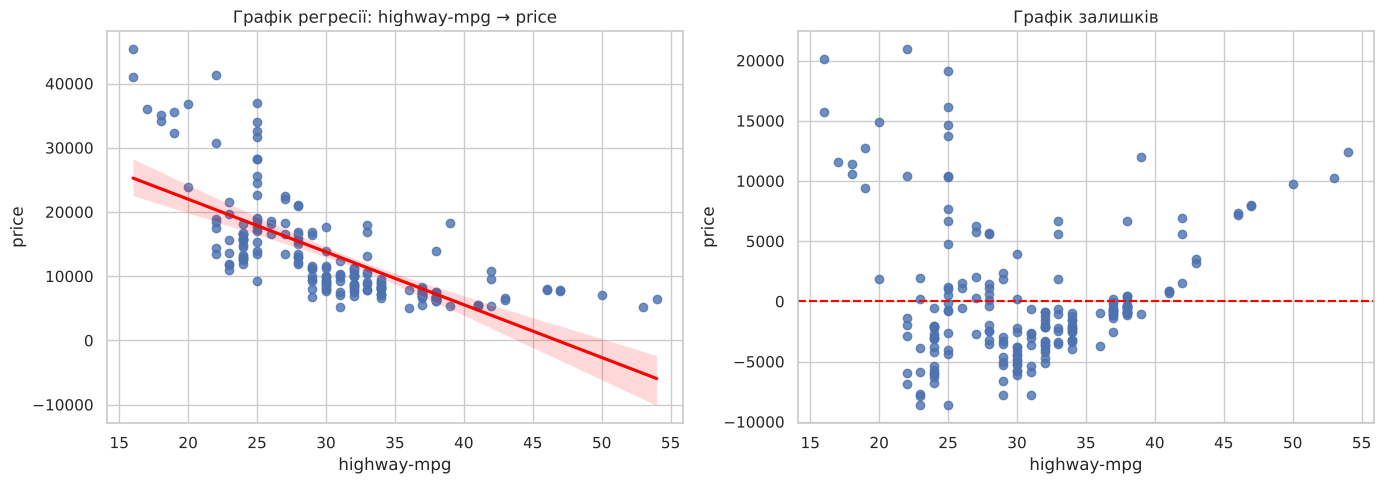

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.regplot(x="highway-mpg", y="price", data=df, ax=axes[0], line_kws={"color": "red"})
axes[0].set_title("Графік регресії: highway-mpg → price")
sns.residplot(x=df["highway-mpg"], y=df["price"], ax=axes[1])
axes[1].axhline(0, color="red", ls="--")
axes[1].set_title("Графік залишків")
plt.tight_layout(); plt.show()

Залишки утворюють дугу, тобто не розкидані випадково. Отже, залежність ціни від `highway-mpg` скоріше **нелінійна**, і лінійна модель тут не найкраща.

### 3.2. Множинна лінійна регресія (MLR)
Модель: $\hat{Y} = a + b_1X_1 + b_2X_2 + b_3X_3 + b_4X_4$, предиктори: `horsepower`, `curb-weight`, `engine-size`, `highway-mpg`.

In [6]:
Z = df[["horsepower", "curb-weight", "engine-size", "highway-mpg"]]
lm_multi = LinearRegression().fit(Z, Y)
print("Intercept:", lm_multi.intercept_)
print(pd.Series(lm_multi.coef_, index=Z.columns, name="коефіцієнт"))

Y_hat_multi = lm_multi.predict(Z)
evaluate("MLR: hp + curb-weight + engine-size + highway-mpg", Y, Y_hat_multi)

Intercept: -15824.038208234462
horsepower     53.610427
curb-weight     4.708864
engine-size    81.472257
highway-mpg    36.396378
Name: коефіцієнт, dtype: float64
MLR: hp + curb-weight + engine-size + highway-mpg:  R² = 0.8094,  MSE = 1.1977e+07


(0.8094130135602673, 11976801.681229586)

Модель із кількома змінними не можна показати однією лінією, тому порівнюємо **розподіл передбачених значень із розподілом фактичних**.

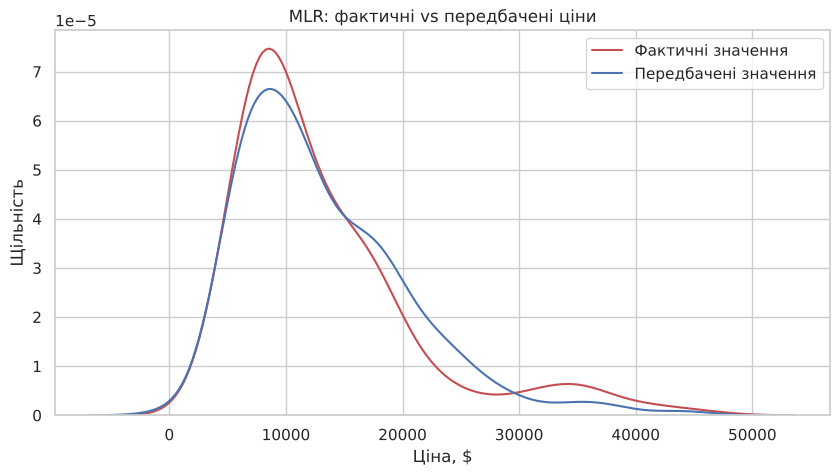

In [7]:
def distribution_plot(actual, predicted, title, labels=("Фактичні значення", "Передбачені значення")):
    plt.figure(figsize=(10, 5))
    sns.kdeplot(actual, color="r", label=labels[0])
    sns.kdeplot(predicted, color="b", label=labels[1])
    plt.title(title); plt.xlabel("Ціна, $"); plt.ylabel("Щільність")
    plt.legend(); plt.show()

distribution_plot(Y, Y_hat_multi, "MLR: фактичні vs передбачені ціни")

Криві розподілів майже збігаються, тож модель MLR непогано відтворює реальні ціни.

### 3.3. Поліноміальна регресія
Поліноміальна регресія — окремий випадок лінійної регресії. Ознаки підносимо до степенів ($x, x^2, x^3, \dots$), а модель залишається лінійною за коефіцієнтами.
Приклад: поліном 3-го степеня для `highway-mpg`.

        3         2
-1.557 x + 204.8 x - 8965 x + 1.379e+05


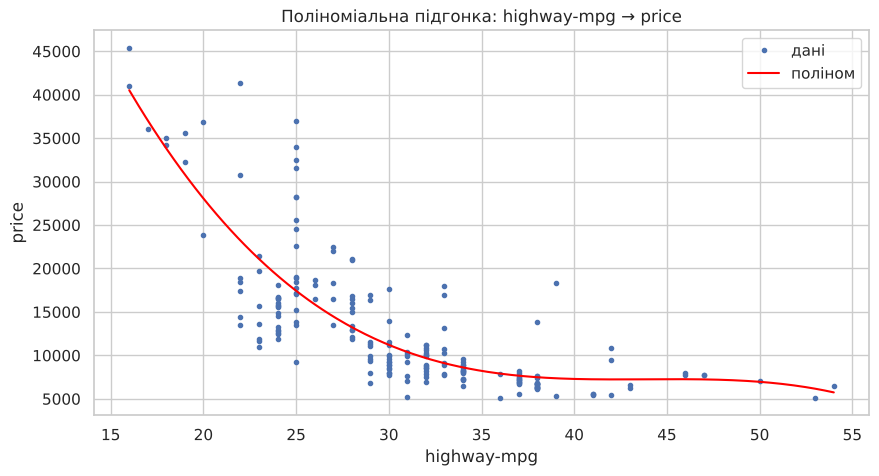

Polynomial (3): highway-mpg:  R² = 0.6742,  MSE = 2.0474e+07


(0.6741946663906517, 20474146.42636122)

In [8]:
def plot_poly(model, x, y, name):
    x_new = np.linspace(x.min(), x.max(), 300)
    plt.figure(figsize=(10, 5))
    plt.plot(x, y, ".", label="дані")
    plt.plot(x_new, model(x_new), "-", color="red", label="поліном")
    plt.title(f"Поліноміальна підгонка: {name} → price")
    plt.xlabel(name); plt.ylabel("price"); plt.legend(); plt.show()

x = df["highway-mpg"]
f3 = np.polyfit(x, Y, 3)
p3 = np.poly1d(f3)
print(p3)
plot_poly(p3, x, Y, "highway-mpg")
evaluate("Polynomial (3): highway-mpg", Y, p3(x))

### 3.4. Pipeline (конвеєр)
Pipeline об'єднує кроки обробки в один об'єкт: **нормалізація (StandardScaler) → поліноміальні ознаки (PolynomialFeatures) → лінійна регресія**.
Так менше коду і менше шансів помилитися (наприклад, забути нормалізувати нові дані перед передбаченням).

In [9]:
pipe = Pipeline([
    ("scale", StandardScaler()),
    ("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
    ("model", LinearRegression()),
])
pipe.fit(Z, Y)
ypipe = pipe.predict(Z)
print("Перші 4 передбачення:", ypipe[:4].round(1))
evaluate("Pipeline (scale + poly 2 + LR): 4 ознаки", Y, ypipe)

Перші 4 передбачення: [13103.4 13103.4 18228.5 10393. ]
Pipeline (scale + poly 2 + LR): 4 ознаки:  R² = 0.8463,  MSE = 9.6558e+06


(0.8463476086131142, 9655770.595172968)

---
# Завдання 3.3

### Завдання 1. Лінійна регресія: `engine-size` (X) → `price` (Y). Чи вдала модель?

In [10]:
lm_es = LinearRegression()
X_es = df[["engine-size"]]
lm_es.fit(X_es, Y)
print(f"Рівняння: price = {lm_es.intercept_:.2f} + {lm_es.coef_[0]:.2f} * engine-size")

Yhat_es = lm_es.predict(X_es)
r2_es, mse_es = evaluate("SLR: engine-size", Y, Yhat_es)
print("Перші 5 передбачень:", Yhat_es[:5].round(0))

Рівняння: price = -7963.34 + 166.86 * engine-size
SLR: engine-size:  R² = 0.7610,  MSE = 1.5021e+07
Перші 5 передбачень: [13728. 13728. 17399. 10224. 14730.]


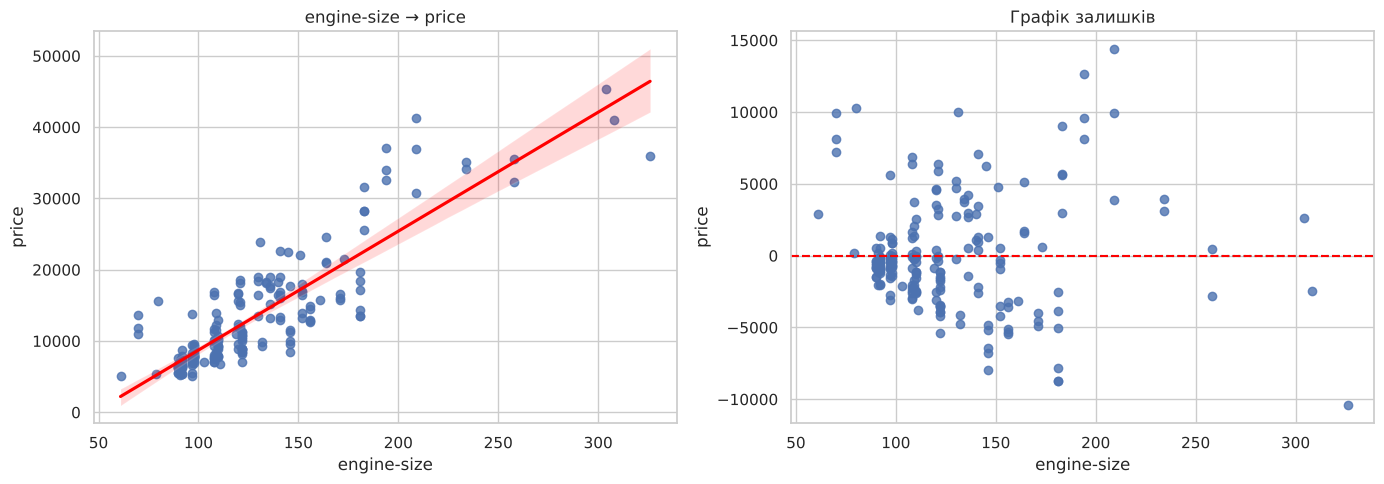

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.regplot(x="engine-size", y="price", data=df, ax=axes[0], line_kws={"color": "red"})
axes[0].set_title("engine-size → price")
sns.residplot(x=df["engine-size"], y=df["price"], ax=axes[1])
axes[1].axhline(0, color="red", ls="--")
axes[1].set_title("Графік залишків")
plt.tight_layout(); plt.show()

**Висновок.** Рівняння моделі: **price ≈ −7963 + 166.86 · engine-size**, тобто кожен додатковий кубічний дюйм об'єму двигуна в середньому додає ≈ 167 $ до ціни.

- R² ≈ **0.761**: модель пояснює ~76% варіації ціни. Це набагато краще, ніж `highway-mpg` (R² ≈ 0.50).
- MSE ≈ **1.50·10⁷** (корінь з MSE ≈ 3 900 $), удвічі менше, ніж у моделі з `highway-mpg`.

**Модель досить вдала** для однієї змінної. Проте залишки зростають для великих двигунів (розкид праворуч більший), тому для точнішого прогнозу варто додати інші ознаки (MLR).

### Завдання 2. Множинна лінійна регресія: `normalized-losses` + `highway-mpg` → `price`

Intercept: 38201.313
normalized-losses      1.497896
highway-mpg         -820.454340
Name: коефіцієнт, dtype: float64
MLR: normalized-losses + highway-mpg:  R² = 0.4966,  MSE = 3.1633e+07


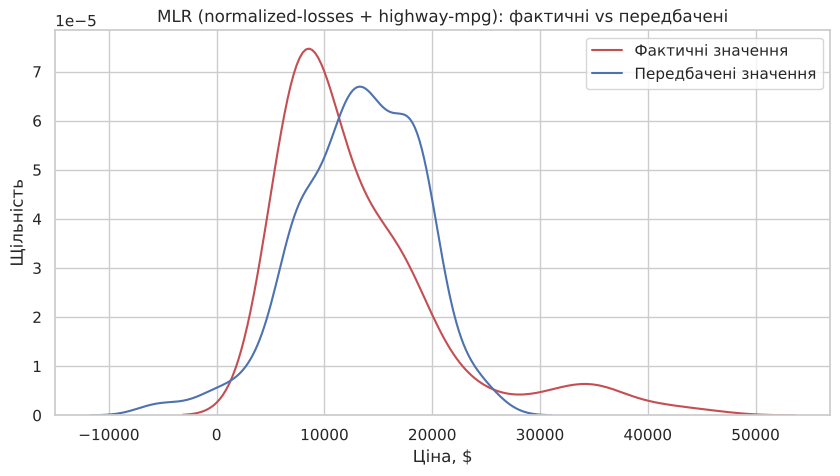

In [12]:
lm2 = LinearRegression()
X2 = df[["normalized-losses", "highway-mpg"]]
lm2.fit(X2, Y)

print("Intercept:", round(lm2.intercept_, 3))
print(pd.Series(lm2.coef_, index=X2.columns, name="коефіцієнт"))

Yhat2 = lm2.predict(X2)
evaluate("MLR: normalized-losses + highway-mpg", Y, Yhat2)
distribution_plot(Y, Yhat2, "MLR (normalized-losses + highway-mpg): фактичні vs передбачені")

**Висновок.** Рівняння: **price ≈ 38201 + 1.50 · normalized-losses − 820.45 · highway-mpg**.

- R² ≈ **0.497**, майже як у простої регресії лише за `highway-mpg` (0.4966). Тобто `normalized-losses` майже нічого не додає до моделі: її коефіцієнт малий, а кореляція з ціною слабка.
- На графіку розподілів передбачені ціни помітно відхиляються від фактичних, особливо в зоні дорогих авто.

Отже, більше змінних не завжди означає кращу модель: предиктори треба вибирати за силою зв'язку з ціною.

### Завдання 3. Поліноміальна модель 11-го порядку
Обрано: **x = `engine-size`** (незалежна), **y = `price`** (залежна).

Коефіцієнти полінома (від старшого степеня):
[-1.24426700e-18  3.13577101e-15 -3.32936224e-12  1.98526493e-09
 -7.41611874e-07  1.82315887e-04 -3.00373520e-02  3.30239889e+00
 -2.35778458e+02  1.02950865e+04 -2.42677827e+05  2.25736742e+06]


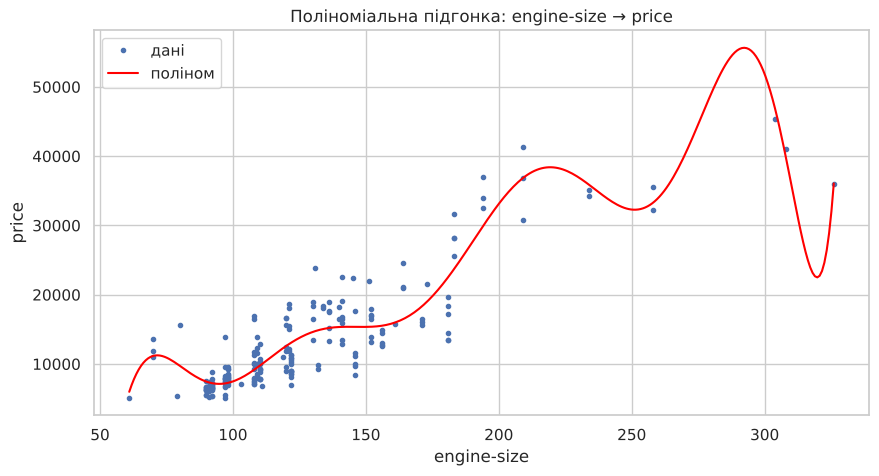

Polynomial (11): engine-size:  R² = 0.8399,  MSE = 1.0059e+07


(0.8399271661470957, 10059241.826644298)

In [13]:
x = df["engine-size"]
f11 = np.polyfit(x, Y, 11)
p11 = np.poly1d(f11)
print("Коефіцієнти полінома (від старшого степеня):")
print(f11)

plot_poly(p11, x, Y, "engine-size")
evaluate("Polynomial (11): engine-size", Y, p11(x))

In [14]:
# Для порівняння: як змінюється R² зі зростанням степеня полінома
rows = []
for d in [1, 2, 3, 5, 8, 11]:
    p = np.poly1d(np.polyfit(x, Y, d))
    rows.append({"степінь": d, "R²": r2_score(Y, p(x)), "MSE": mean_squared_error(Y, p(x))})
pd.DataFrame(rows)

,степінь,R²,MSE
0,1,0.760969,1.502113e+07
1,2,0.761042,1.501655e+07
2,3,0.790152,1.318720e+07
3,5,0.790610,1.315843e+07
4,8,0.825299,1.097848e+07
5,11,0.839927,1.005924e+07


**Висновок.** Поліном 11-го порядку дає R² ≈ **0.84** проти 0.76 у лінійної моделі, тобто на навчальних даних він точніший.
Але крива «звивається» там, де мало точок: між 260 і 300 куб. дюймів вона дає ≈ 55 000 $, а біля 320 різко падає до ≈ 22 000 $, хоча реальних даних, які б це підтверджували, немає. Модель підлаштовується під окремі автомобілі, а не під загальну тенденцію. Це ознака **перенавчання (overfitting)**: на нових даних така модель може передбачати гірше, ніж простіша. Високий степінь полінома треба застосовувати обережно й перевіряти модель на тестових даних (це тема лабораторної №4).

### Завдання 4. Усі розглянуті моделі для обраних змінних та висновки
Для порівняння будуємо **SLR, MLR, поліноміальну регресію та Pipeline** на основі сильних предикторів з лабораторної №2 (`horsepower`, `curb-weight`, `engine-size`, `highway-mpg`).

In [15]:
results_t4 = []
def eval_t4(name, y_pred):
    results_t4.append({"модель": name, "R²": r2_score(Y, y_pred), "MSE": mean_squared_error(Y, y_pred)})

# 1) SLR для кожної змінної окремо
for col in ["horsepower", "curb-weight", "engine-size", "highway-mpg"]:
    m = LinearRegression().fit(df[[col]], Y)
    eval_t4(f"SLR: {col}", m.predict(df[[col]]))

# 2) Поліноміальна регресія 3-го степеня (одна змінна)
for col in ["horsepower", "engine-size", "highway-mpg"]:
    p = np.poly1d(np.polyfit(df[col], Y, 3))
    eval_t4(f"Polynomial (3): {col}", p(df[col]))

# 3) MLR з 4 змінними
feats = ["horsepower", "curb-weight", "engine-size", "highway-mpg"]
mlr = LinearRegression().fit(df[feats], Y)
eval_t4("MLR: 4 змінні", mlr.predict(df[feats]))

# 4) Pipeline: нормалізація + поліном 2-го степеня + LR на 4 змінних
pipe2 = Pipeline([("scale", StandardScaler()),
                  ("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
                  ("model", LinearRegression())]).fit(df[feats], Y)
eval_t4("Pipeline (poly 2): 4 змінні", pipe2.predict(df[feats]))

table_t4 = pd.DataFrame(results_t4).sort_values("R²", ascending=False).reset_index(drop=True)
table_t4["RMSE, $"] = np.sqrt(table_t4["MSE"]).round(0)
table_t4.style.format({"R²": "{:.4f}", "MSE": "{:.3e}", "RMSE, $": "{:.0f}"}).background_gradient(subset=["R²"], cmap="Greens")

,модель,R²,MSE,"RMSE, $"
0,Pipeline (poly 2): 4 змінні,0.8463,9.656e+06,3107
1,MLR: 4 змінні,0.8094,1.198e+07,3461
2,Polynomial (3): engine-size,0.7902,1.319e+07,3631
3,SLR: engine-size,0.7610,1.502e+07,3876
4,SLR: curb-weight,0.6962,1.909e+07,4369
5,Polynomial (3): highway-mpg,0.6742,2.047e+07,4525
6,Polynomial (3): horsepower,0.6629,2.118e+07,4602
7,SLR: horsepower,0.6556,2.164e+07,4652
8,SLR: highway-mpg,0.4966,3.164e+07,5625


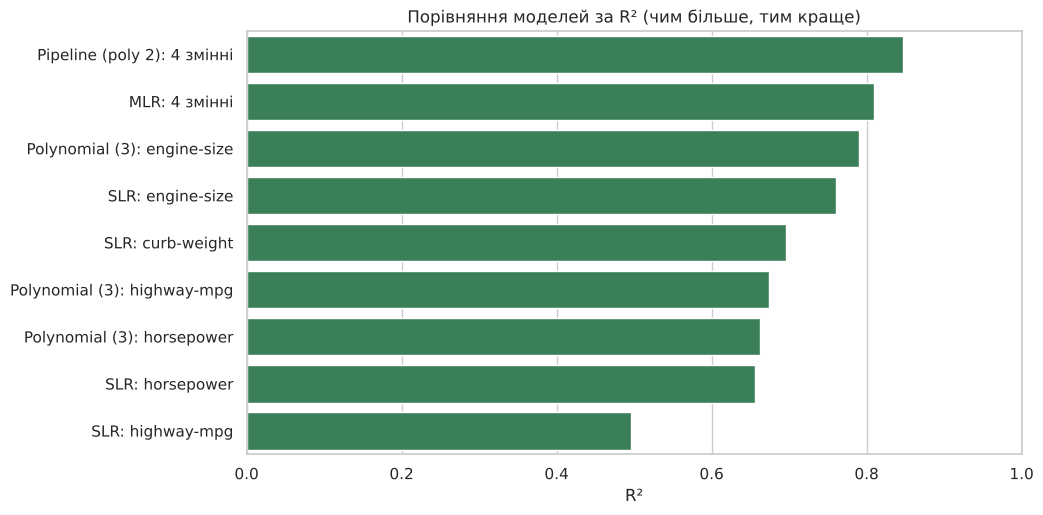

In [16]:
plt.figure(figsize=(10, 5.5))
sns.barplot(y="модель", x="R²", data=table_t4, color="seagreen")
plt.title("Порівняння моделей за R² (чим більше, тим краще)")
plt.xlim(0, 1); plt.ylabel(""); plt.show()

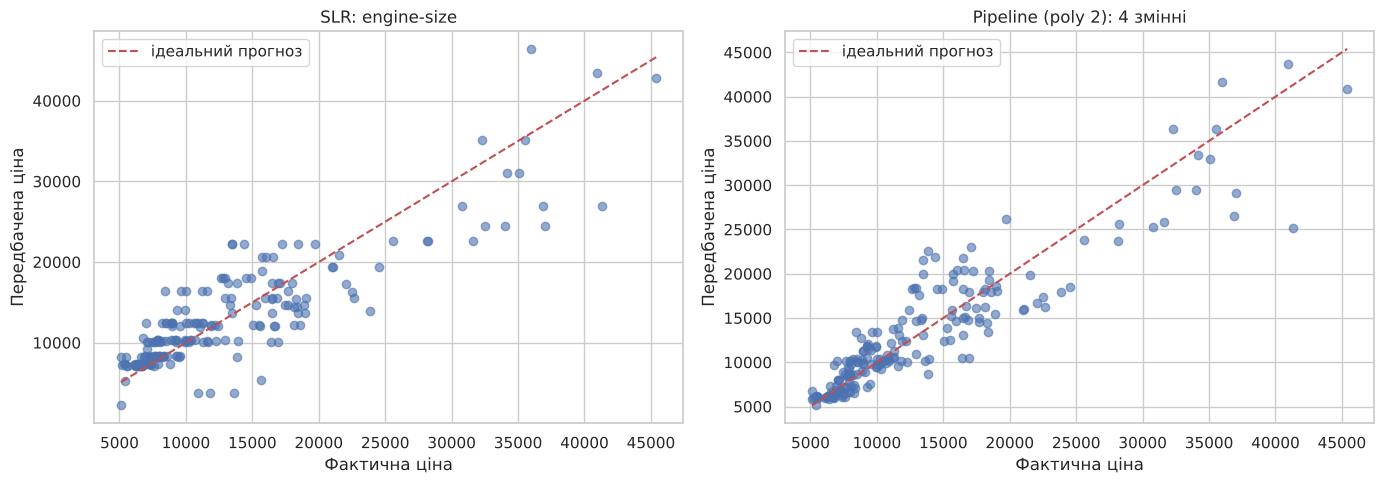

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, pred) in zip(axes, [("SLR: engine-size", lm_es.predict(df[["engine-size"]])),
                                    ("Pipeline (poly 2): 4 змінні", pipe2.predict(df[feats]))]):
    ax.scatter(Y, pred, alpha=0.6)
    ax.plot([Y.min(), Y.max()], [Y.min(), Y.max()], "r--", label="ідеальний прогноз")
    ax.set_xlabel("Фактична ціна"); ax.set_ylabel("Передбачена ціна"); ax.set_title(name); ax.legend()
plt.tight_layout(); plt.show()

**Висновки до завдання 4:**

1. **Серед простих моделей (SLR)** найкраща — за `engine-size` (R² ≈ 0.76), найгірша — за `highway-mpg` (R² ≈ 0.50).
2. **Поліноміальна регресія** покращує модель, коли зв'язок нелінійний. Для `highway-mpg` R² зростає з 0.50 до 0.67, а MSE падає з 3.16·10⁷ до 2.05·10⁷ (це збігається з прикладом у методичці).
3. **MLR** з 4 змінними (R² ≈ 0.81, MSE ≈ 1.2·10⁷) краща за будь-яку модель з однією змінною: кожна ознака додає інформацію.
4. **Pipeline** (нормалізація + поліном 2-го степеня + регресія на 4 змінних) дає найвищий R² і найменший MSE серед усіх моделей.
5. Порівнювати моделі треба за **обома метриками разом**: кращою вважаємо модель з **більшим R²** і **меншим MSE**.
6. Застереження: усі метрики тут пораховані на тих самих даних, на яких моделі навчались. Складніші моделі (поліноми високих степенів) можуть бути перенавчені, тому остаточний вибір треба перевіряти на тестовій вибірці.

---
## 4. Використання моделі для передбачення
Навчена модель передбачає ціну для **нових** автомобілів, яких не було в датасеті. Для цього викликаємо `predict()`.

In [18]:
# Прогноз ціни для нових значень об'єму двигуна (SLR з завдання 1)
new_engine = pd.DataFrame({"engine-size": [90, 120, 150, 200, 250]})
new_engine["прогноз ціни, $"] = lm_es.predict(new_engine[["engine-size"]]).round(0)
new_engine

,engine-size,"прогноз ціни, $"
0,90,7054.0
1,120,12060.0
2,150,17066.0
3,200,25409.0
4,250,33752.0


In [19]:
# Прогноз для конкретного нового авто за найкращою моделлю (Pipeline з 4 ознаками)
new_car = pd.DataFrame([{"horsepower": 120, "curb-weight": 2700, "engine-size": 140, "highway-mpg": 28}])
print("Прогнозована ціна нового авто:", round(pipe2.predict(new_car)[0]), "$")

Прогнозована ціна нового авто: 14129 $


## 5. Підсумок (усі моделі з теоретичної частини та завдань)

In [20]:
summary = pd.DataFrame(results).drop_duplicates("модель").sort_values("R²", ascending=False).reset_index(drop=True)
summary.style.format({"R²": "{:.4f}", "MSE": "{:.3e}"})

,модель,R²,MSE
0,Pipeline (scale + poly 2 + LR): 4 ознаки,0.8463,9.656e+06
1,Polynomial (11): engine-size,0.8399,1.006e+07
2,MLR: hp + curb-weight + engine-size + highway-mpg,0.8094,1.198e+07
3,SLR: engine-size,0.7610,1.502e+07
4,Polynomial (3): highway-mpg,0.6742,2.047e+07
5,MLR: normalized-losses + highway-mpg,0.4966,3.163e+07
6,SLR: highway-mpg,0.4966,3.164e+07


**Висновок до лабораторної роботи.**
У роботі побудовано й порівняно моделі для прогнозування ціни автомобіля: просту лінійну регресію, множинну лінійну регресію, поліноміальну регресію (3-го та 11-го порядку) і Pipeline (StandardScaler + PolynomialFeatures + LinearRegression). Якість моделей оцінено за R² та MSE, а також візуально: графіки регресії, залишків і розподілів.

Найкращі результати дають моделі з кількома сильними предикторами (MLR і Pipeline, R² > 0.8). Модель з `normalized-losses` + `highway-mpg` слабка (R² ≈ 0.5), бо ці змінні погано пов'язані з ціною. Поліном 11-го порядку точніший на навчальних даних, але має ознаки перенавчання.

---
# 3.4. Контрольні запитання

**1. Що таке лінійна регресія?**
Лінійна регресія — метод моделювання залежності між залежною змінною *Y* (відгуком) і незалежною змінною *X* (предиктором) за допомогою лінійної функції $\hat{Y} = a + bX$, де *a* — вільний член (intercept), *b* — коефіцієнт нахилу. Якщо *X* одна змінна, регресію називають **простою**. Параметри моделі найчастіше оцінюють **методом найменших квадратів (МНК)**: підбирають такі *a* і *b*, щоб сума квадратів залишків $\sum (y_i - \hat{y}_i)^2$ була мінімальною. У sklearn — `LinearRegression().fit(X, Y)`.

**2. Що таке множинна регресія?**
Множинна лінійна регресія — узагальнення простої регресії на випадок двох і більше предикторів: $\hat{Y} = a + b_1X_1 + b_2X_2 + \dots + b_nX_n$. Вона пояснює зв'язок однієї залежної змінної з кількома незалежними. Більшість реальних моделей саме такі. Візуалізувати її однією лінією не можна, тому використовують графік розподілу фактичних і передбачених значень. Поліноміальна регресія — окремий випадок множинної, де «додаткові» змінні — це степені вихідної ($x^2, x^3, \dots$).

**3. Що таке R²? MSE?**
- **R² (коефіцієнт детермінації)** — частка варіації залежної змінної, яку пояснює модель: $R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$. Зазвичай від 0 до 1: 1 — модель пояснює всі зміни, 0 — модель не краща за просте середнє (на нових даних може бути навіть від'ємним).
- **MSE (середня квадратична помилка)** — середнє значення квадратів різниць між фактичними і передбаченими значеннями: $MSE = \frac{1}{n}\sum (y_i - \hat{y}_i)^2$. Завжди ≥ 0, чим менше, тим краще. Вимірюється в квадратних одиницях (для ціни це $²), тому часто беруть корінь **RMSE**, який має ті самі одиниці, що й *y*.

**4. Як зрозуміти, яка модель краще робить передбачення?**
Порівнюємо метрики: краща модель має **більший R²** і **менший MSE**, і дивимося на обидві разом. Додатково дивимося на графіки: на графіку залишків точки мають бути випадково розкидані навколо нуля, а на графіку розподілів передбачені значення мають збігатися з фактичними. Більше змінних або вищий степінь полінома не завжди краще: модель може перенавчитися, тому остаточно якість перевіряють на **тестових даних**, яких модель не бачила (train/test split, крос-валідація).

**5. Як використати побудовану модель? І для чого потрібно її використовувати?**
Після навчання (`fit`) модель викликають методом **`predict()`** для нових даних з тими самими ознаками, наприклад `lm.predict(pd.DataFrame({'engine-size': [150]}))`. Модель потрібна, щоб **прогнозувати** значення, яких ми ще не знаємо: оцінити ціну нового чи вживаного авто за характеристиками, встановити справедливу ціну під час продажу, перевірити, чи не завищена ціна, і зрозуміти, які фактори та наскільки впливають на результат (коефіцієнти моделі).